# Week 1 - Linear Regression with Polynomial Terms, Interaction terms, Multicollinearity, variance inflation factor and regression, and categorical and continuous features.

## Dataset used 

### BRFSS 2015 Diabetes Health Indicators

## Goal

The notebook covers the week 1 requirements of Linear Regression, Polynomial Terms, Interaction Terms, multicollinearity, Variance Influence Factor(VIF), categorical and continuous features.

The overall goal of my project is to understand and predict diabetes using health and lifestyle indicators, with Diabetes_binary as the primary classification outcome. However, Week 1 focuses on linear regression, polynomial terms, interaction terms, multicollinearity, and VIF. Because standard linear regression is designed for a continuous outcome, I use BMI as the response variable for this Week 1 exercise rather than changing the overall project objective. BMI is one of the health indicators contained in the diabetes dataset and is relevant to the broader diabetes-risk analysis.

This Week 1 analysis therefore serves as an exploratory regression exercise within the larger diabetes project. I examine whether other health characteristics help explain variation in BMI and use the analysis to understand nonlinear relationships, interactions, and multicollinearity. When classification methods are introduced, I will use Diabetes_binary as the target variable for directly predicting diabetes.

## Week 1 Question: How are demographic and health indicators associated with BMI and do polynomial and interaction terms improve the linear regression models?

### Import Libraries and Health dataset

In [1]:
# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [2]:
# 2. Load the health dataset

health_url = (
    "https://raw.githubusercontent.com/jeganart/"
    "healthdatasetmilestone3/refs/heads/main/"
    "diabetes_binary_health_indicators_BRFSS2015.csv"
)

df = pd.read_csv(health_url)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### Basic EDA and Feature analysis
BMI is the continuous outcome. Age, PhysHlth, and MentHlth are numeric/ordered features. HighBP, HighChol, Smoker, PhysActivity, and Sex are binary categorical features coded as 0 and 1.


Missing values:
BMI             0
Age             0
PhysHlth        0
MentHlth        0
HighBP          0
HighChol        0
Smoker          0
PhysActivity    0
Sex             0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
PhysHlth,253680.0,4.242081,8.717951,0.0,0.0,0.0,3.0,30.0
MentHlth,253680.0,3.184772,7.412847,0.0,0.0,0.0,2.0,30.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Sex,253680.0,0.440342,0.496429,0.0,0.0,0.0,1.0,1.0


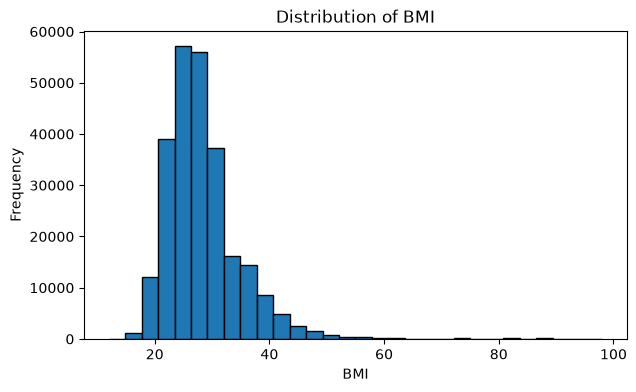

In [3]:
# 3. Keep the relevant variables.

columns = [
    "BMI", "Age", "PhysHlth", "MentHlth",
    "HighBP", "HighChol", "Smoker", "PhysActivity", "Sex"
]

week1_df = df[columns].dropna().copy()

print("Missing values:")
print(week1_df.isnull().sum())
display(week1_df.describe().T)

plt.figure(figsize=(7, 4))
plt.hist(week1_df["BMI"], bins=30, edgecolor="black")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("Distribution of BMI")
plt.show()

## Baseline Linear Regression
I will fit a multiple linear regression using both numeric and categorical predictors to generate the baseline before adding polynomial and interaction terms

In [4]:
# 4. Split data into training and test sets

train_df, test_df = train_test_split(
    week1_df,
    test_size=0.20,
    random_state=42
)

baseline_model = smf.ols(
    "BMI ~ Age + PhysHlth + MentHlth + HighBP + HighChol + "
    "Smoker + PhysActivity + Sex",
    data=train_df
).fit()

baseline_pred = baseline_model.predict(test_df)

baseline_rmse = np.sqrt(mean_squared_error(test_df["BMI"], baseline_pred))
baseline_mae = mean_absolute_error(test_df["BMI"], baseline_pred)
baseline_r2 = r2_score(test_df["BMI"], baseline_pred)

print("Baseline RMSE:", baseline_rmse)
print("Baseline MAE:", baseline_mae)
print("Baseline R-squared:", baseline_r2)

Baseline RMSE: 6.3042234875675485
Baseline MAE: 4.477593430129073
Baseline R-squared: 0.0858884777172555


I used BMI as the continuous outcome and included both continuous health measures and binary categorical features. The baseline multiple linear regression produced an RMSE of 6.3042, MAE of 4.4776, and R-squared of 0.0859. This means that the baseline predictors explained only about 8.6% of the variation in BMI, **indicating that these health indicators alone have limited ability to predict an individual's BMI.**

## Polynomial Term

A polynomial term allows a curved relationship instead of assuming that the relationship is completely linear. I center Age first and then create Age squared. Centering also helps reduce unnecessary correlation between Age and Age squared.

In [5]:
# 5. Center Age and create Age squared

age_mean = train_df["Age"].mean()

train_df = train_df.copy()
test_df = test_df.copy()

train_df["Age_centered"] = train_df["Age"] - age_mean
test_df["Age_centered"] = test_df["Age"] - age_mean

train_df["Age_squared"] = train_df["Age_centered"] ** 2
test_df["Age_squared"] = test_df["Age_centered"] ** 2

polynomial_model = smf.ols(
    "BMI ~ Age_centered + Age_squared + PhysHlth + MentHlth + "
    "HighBP + HighChol + Smoker + PhysActivity + Sex",
    data=train_df
).fit()

polynomial_pred = polynomial_model.predict(test_df)

poly_rmse = np.sqrt(mean_squared_error(test_df["BMI"], polynomial_pred))
poly_mae = mean_absolute_error(test_df["BMI"], polynomial_pred)
poly_r2 = r2_score(test_df["BMI"], polynomial_pred)

print("Polynomial RMSE:", poly_rmse)
print("Polynomial MAE:", poly_mae)
print("Polynomial R-squared:", poly_r2)


Polynomial RMSE: 6.267742051079038
Polynomial MAE: 4.44497206443347
Polynomial R-squared: 0.09643747291065208



Adding the centered Age-squared polynomial term improved the model slightly. RMSE decreased from 6.3042 to 6.2677, MAE decreased from 4.4776 to 4.4450, and R-squared increased from 0.0859 to 0.0964. This suggests that the relationship between age and BMI is not completely linear and that allowing some curvature captured additional information. I then added an Age × HighBP interaction to test whether the relationship between age and BMI differed for people with and without high blood pressure. This produced the best results, with RMSE = 6.2596, MAE = 4.4336, and R-squared = 0.0988. However, **the improvement over the polynomial model was small.** Therefore, the interaction added some predictive information, but not enough to substantially change overall model performance.


## Interaction Term

An interaction tests whether the relationship between one predictor and BMI changes depending on another predictor. I use **Age × HighBP** to test whether the age-BMI relationship differs for people with and without high blood pressure.

In [6]:
# 6. Add Age and HighBP interaction

interaction_model = smf.ols(
    "BMI ~ Age_centered + Age_squared + HighBP + "
    "Age_centered:HighBP + PhysHlth + MentHlth + "
    "HighChol + Smoker + PhysActivity + Sex",
    data=train_df
).fit()

interaction_pred = interaction_model.predict(test_df)

interaction_rmse = np.sqrt(mean_squared_error(test_df["BMI"], interaction_pred))
interaction_mae = mean_absolute_error(test_df["BMI"], interaction_pred)
interaction_r2 = r2_score(test_df["BMI"], interaction_pred)

print("Interaction RMSE:", interaction_rmse)
print("Interaction MAE:", interaction_mae)
print("Interaction R-squared:", interaction_r2)


Interaction RMSE: 6.2596261078571045
Interaction MAE: 4.433634021640617
Interaction R-squared: 0.09877595917197113


## Multicollinearity and VIF

Multicollinearity occurs when predictors contain overlapping information and are strongly related. This can make regression coefficients unstable. I use Variance Inflation Factor (VIF) as a diagnostic. Higher VIF values indicate greater multicollinearity.


In [7]:
# 7. Calculate VIF

vif_columns = [
    "Age_centered", "Age_squared", "PhysHlth", "MentHlth",
    "HighBP", "HighChol", "Smoker", "PhysActivity", "Sex"
]

X_vif = train_df[vif_columns].copy()
X_vif.insert(0, "Intercept", 1)

vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results.round(3))

,Feature,VIF
0,Intercept,8.801
1,Age_centered,1.315
2,Age_squared,1.109
3,PhysHlth,1.221
4,MentHlth,1.188
5,HighBP,1.225
6,HighChol,1.154
7,Smoker,1.050
8,PhysActivity,1.069
9,Sex,1.027


The VIF results showed no concerning multicollinearity among the predictors. All predictor VIF values were approximately 1.03–1.32, including Age_centered at 1.315 and Age-squared at 1.109. Centering Age before creating the squared term helped prevent unnecessary correlation between the polynomial terms. Overall, the analysis showed that polynomial and interaction terms can improve a linear model, but additional complexity does not necessarily produce a large improvement in prediction. 

## Model Comparison

I compare the models on the same test data. Lower RMSE and MAE are better, while higher R-squared is better.


,Model,RMSE,MAE,R-squared
0,Baseline Linear,6.3042,4.4776,0.0859
1,Polynomial,6.2677,4.4450,0.0964
2,Polynomial + Interaction,6.2596,4.4336,0.0988


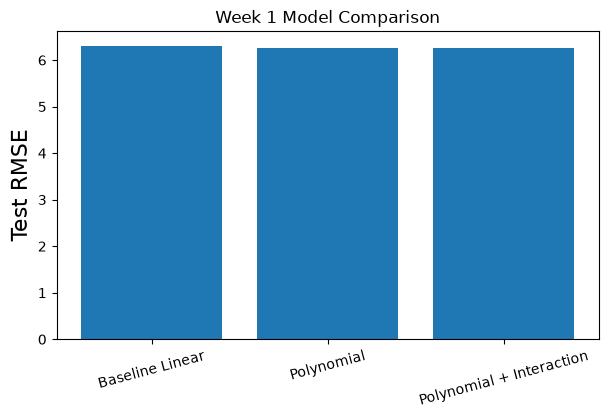

In [8]:
# 8. Compare model performance

comparison = pd.DataFrame({
    "Model": ["Baseline Linear", "Polynomial", "Polynomial + Interaction"],
    "RMSE": [baseline_rmse, poly_rmse, interaction_rmse],
    "MAE": [baseline_mae, poly_mae, interaction_mae],
    "R-squared": [baseline_r2, poly_r2, interaction_r2]
})

display(comparison.round(4))

plt.figure(figsize=(7, 4))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.ylabel("Test RMSE",fontsize=16)
plt.title("Week 1 Model Comparison")
plt.xticks(rotation=15)
plt.show()

The polynomial-plus-interaction model performed best, but its R-squared of approximately 0.099 means that about 90% of the variation in BMI remains unexplained by this model. This suggests that additional factors or different modeling approaches would be needed for stronger BMI prediction.

## Week 1 Summary

I used linear regression with both continuous/numeric and categorical features. I then added a polynomial term to allow a nonlinear relationship between Age and BMI and an interaction term to test whether the Age-BMI relationship changes with high blood pressure status.

I also evaluated multicollinearity using VIF. Centering Age before creating Age squared helps reduce unnecessary correlation between the polynomial terms. Finally, I compared all three models using test-set RMSE, MAE, and R-squared.

The main lesson is that polynomial and interaction terms can make a linear regression model more flexible, but additional complexity should be supported by improved results. VIF is useful for checking whether the added predictors create multicollinearity.

I expected polynomial and interaction terms to improve the baseline regression because health relationships are not necessarily linear. The results supported this expectation, but the magnitude of improvement was smaller than expected. R-squared increased only from 0.0859 to 0.0988, showing that additional model complexity captured some additional information but did not overcome the limited explanatory power of the selected predictors.